# 02 — Product Behavior Analysis

**Goal:** Build a user-level analytical dataset and investigate funnel behavior,
feature adoption, conversion, activation speed, sessions and churn.

Activation is defined as `project_created`.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

users = pd.read_csv("users.csv")
events = pd.read_csv("events.csv")
sessions = pd.read_csv("sessions.csv")
subscriptions = pd.read_csv("subscriptions.csv")

users["signup_date"] = pd.to_datetime(users["signup_date"], errors="coerce")
events["event_timestamp"] = pd.to_datetime(events["event_timestamp"], errors="coerce")
sessions["session_start"] = pd.to_datetime(sessions["session_start"], errors="coerce")
sessions["session_end"] = pd.to_datetime(sessions["session_end"], errors="coerce")

for col in ["trial_start_date", "subscription_date", "cancel_date"]:
    subscriptions[col] = pd.to_datetime(subscriptions[col], errors="coerce")


## 1. Event distribution


In [3]:
events["event_name"].value_counts()


event_name
login                    66195
file_uploaded            25452
dashboard_created         9323
collaboration_used        8048
project_created           6314
report_exported           3738
integration_connected     2410
Name: count, dtype: int64

## 2. Build user-level master table


In [4]:
activated_users = (
    events.loc[events["event_name"] == "project_created", "user_id"]
    .drop_duplicates()
)

users["activated"] = users["user_id"].isin(activated_users).astype(int)

subscriptions["trial"] = subscriptions["trial_start_date"].notna().astype(int)
subscriptions["paid"] = subscriptions["subscription_date"].notna().astype(int)
subscriptions["churned"] = subscriptions["cancel_date"].notna().astype(int)

user_analysis = users.merge(
    subscriptions[
        [
            "user_id", "trial", "paid", "churned", "plan", "monthly_price",
            "trial_start_date", "subscription_date", "cancel_date"
        ]
    ],
    on="user_id",
    how="left"
)

user_analysis[["trial", "paid", "churned"]] = (
    user_analysis[["trial", "paid", "churned"]]
    .fillna(0)
    .astype(int)
)

user_analysis[["activated", "trial", "paid", "churned"]].sum()


activated    6314
trial        3097
paid         1972
churned       267
dtype: int64

## 3. Feature adoption


In [5]:
feature_events = events.dropna(subset=["feature_name"]).copy()

feature_adoption = (
    feature_events.groupby("feature_name")["user_id"]
    .nunique()
    .reset_index(name="users")
)

total_activated = user_analysis["activated"].sum()

feature_adoption["adoption_rate"] = (
    feature_adoption["users"] / total_activated * 100
).round(2)

feature_adoption = feature_adoption.sort_values(
    "adoption_rate", ascending=False
)

feature_adoption


,feature_name,users,adoption_rate
1,dashboard,3149,49.87
0,collaboration,2252,35.67
2,export,1689,26.75
3,integration,1165,18.45


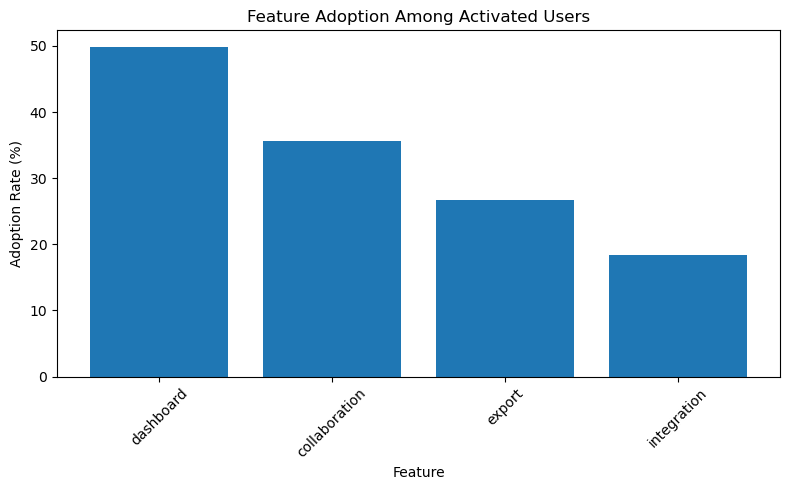

In [8]:
plt.figure(figsize=(8, 5))
plt.bar(feature_adoption["feature_name"], feature_adoption["adoption_rate"])
plt.title("Feature Adoption Among Activated Users")
plt.xlabel("Feature")
plt.ylabel("Adoption Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 4. Feature adoption vs trial, paid conversion and churn


In [9]:
feature_users = feature_events[["user_id", "feature_name"]].drop_duplicates()

feature_conversion = feature_users.merge(
    user_analysis[["user_id", "activated", "trial", "paid", "churned"]],
    on="user_id",
    how="left"
)

feature_summary = (
    feature_conversion.groupby("feature_name")
    .agg(
        feature_adopters=("user_id", "nunique"),
        trial_users=("trial", "sum"),
        paid_users=("paid", "sum")
    )
    .reset_index()
)

feature_summary["trial_conversion_rate"] = (
    feature_summary["trial_users"] / feature_summary["feature_adopters"] * 100
).round(2)

feature_summary["paid_conversion_rate"] = (
    feature_summary["paid_users"] / feature_summary["feature_adopters"] * 100
).round(2)

paid_feature_users = feature_conversion[feature_conversion["paid"] == 1]

churn_feature = (
    paid_feature_users.groupby("feature_name")
    .agg(
        paid_feature_users=("user_id", "nunique"),
        churned_users=("churned", "sum")
    )
    .reset_index()
)

churn_feature["churn_rate"] = (
    churn_feature["churned_users"] / churn_feature["paid_feature_users"] * 100
).round(2)

feature_summary = feature_summary.merge(
    churn_feature[["feature_name", "paid_feature_users", "churn_rate"]],
    on="feature_name",
    how="left"
)

feature_summary.sort_values("paid_conversion_rate", ascending=False)


,feature_name,feature_adopters,trial_users,paid_users,trial_conversion_rate,paid_conversion_rate,paid_feature_users,churn_rate
3,integration,1165,666,529,57.17,45.41,529,7.56
0,collaboration,2252,1158,854,51.42,37.92,854,9.02
2,export,1689,970,618,57.43,36.59,618,12.94
1,dashboard,3149,1676,1071,53.22,34.01,1071,13.82


**Interpretation rule:** These results show association, not causation.
Do not claim that using a feature *causes* conversion or retention.


## 5. Time to activation


In [10]:
first_activation = (
    events.loc[events["event_name"] == "project_created"]
    .groupby("user_id", as_index=False)["event_timestamp"]
    .min()
    .rename(columns={"event_timestamp": "activation_time"})
)

activation_analysis = users.merge(
    first_activation,
    on="user_id",
    how="inner"
)

activation_analysis["hours_to_activation"] = (
    activation_analysis["activation_time"] - activation_analysis["signup_date"]
).dt.total_seconds() / 3600

activation_analysis["hours_to_activation"].describe()


count    6314.000000
mean        3.998099
std         2.014913
min         1.000000
25%         2.000000
50%         4.000000
75%         6.000000
max         7.000000
Name: hours_to_activation, dtype: float64

In [11]:
activation_by_channel = (
    activation_analysis.groupby("acquisition_channel")
    .agg(
        activated_users=("user_id", "nunique"),
        avg_hours_to_activation=("hours_to_activation", "mean"),
        median_hours_to_activation=("hours_to_activation", "median")
    )
    .reset_index()
)

activation_by_channel[
    ["avg_hours_to_activation", "median_hours_to_activation"]
] = activation_by_channel[
    ["avg_hours_to_activation", "median_hours_to_activation"]
].round(2)

activation_by_channel


,acquisition_channel,activated_users,avg_hours_to_activation,median_hours_to_activation
0,Organic,1913,4.01,4.0
1,Paid Search,1357,3.98,4.0
2,Partner,668,3.99,4.0
3,Referral,1201,3.92,4.0
4,Social,1175,4.08,4.0


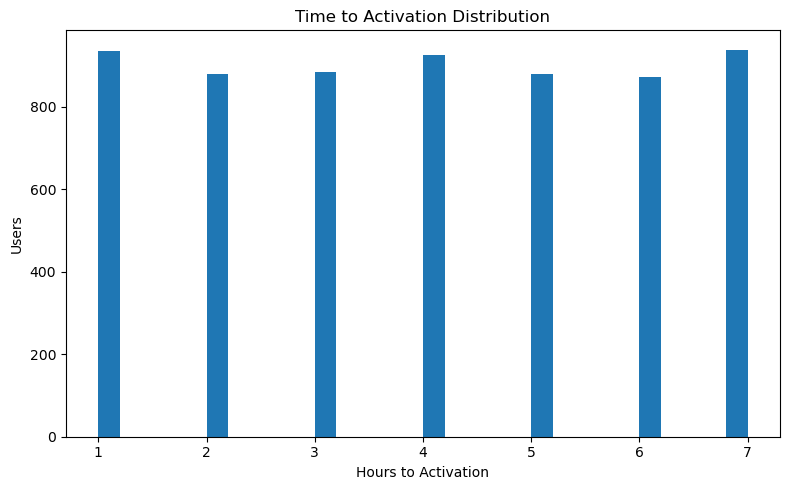

In [12]:
plt.figure(figsize=(8, 5))
plt.hist(activation_analysis["hours_to_activation"].dropna(), bins=30)
plt.title("Time to Activation Distribution")
plt.xlabel("Hours to Activation")
plt.ylabel("Users")
plt.tight_layout()
plt.show()


## 6. Funnel performance by segment


In [13]:
def build_segment_summary(df, column):
    summary = (
        df.groupby(column)
        .agg(
            signups=("user_id", "nunique"),
            activated=("activated", "sum"),
            trials=("trial", "sum"),
            paid=("paid", "sum")
        )
        .reset_index()
    )

    summary["activation_rate"] = (
        summary["activated"] / summary["signups"] * 100
    ).round(2)

    summary["trial_conversion_rate"] = (
        summary["trials"] / summary["activated"].replace(0, np.nan) * 100
    ).round(2)

    summary["paid_conversion_rate"] = (
        summary["paid"] / summary["trials"].replace(0, np.nan) * 100
    ).round(2)

    return summary

channel_summary = build_segment_summary(user_analysis, "acquisition_channel")
device_summary = build_segment_summary(user_analysis, "device")
company_summary = build_segment_summary(user_analysis, "company_size")

display(channel_summary)
display(device_summary)
display(company_summary)


,acquisition_channel,signups,activated,trials,paid,activation_rate,trial_conversion_rate,paid_conversion_rate
0,Organic,2947,1913,899,603,64.91,46.99,67.07
1,Paid Search,2516,1357,662,377,53.93,48.78,56.95
2,Partner,985,668,330,210,67.82,49.40,63.64
3,Referral,1686,1201,657,432,71.23,54.70,65.75
4,Social,1866,1175,549,350,62.97,46.72,63.75


,device,signups,activated,trials,paid,activation_rate,trial_conversion_rate,paid_conversion_rate
0,Desktop,6464,4246,2145,1361,65.69,50.52,63.45
1,Mobile,3536,2068,952,611,58.48,46.03,64.18


,company_size,signups,activated,trials,paid,activation_rate,trial_conversion_rate,paid_conversion_rate
0,Large,1463,947,494,373,64.73,52.16,75.51
1,Medium,3003,1908,972,616,63.54,50.94,63.37
2,Small,5534,3459,1631,983,62.50,47.15,60.27


## 7. Acquisition channel × device


In [14]:
channel_device_summary = (
    user_analysis.groupby(["acquisition_channel", "device"])
    .agg(
        signups=("user_id", "nunique"),
        activated=("activated", "sum")
    )
    .reset_index()
)

channel_device_summary["activation_rate"] = (
    channel_device_summary["activated"]
    / channel_device_summary["signups"] * 100
).round(2)

channel_device_summary.sort_values("activation_rate")


,acquisition_channel,device,signups,activated,activation_rate
3,Paid Search,Mobile,888,422,47.52
2,Paid Search,Desktop,1628,935,57.43
5,Partner,Mobile,324,190,58.64
9,Social,Mobile,685,412,60.15
1,Organic,Mobile,1038,647,62.33
8,Social,Desktop,1181,763,64.61
7,Referral,Mobile,601,397,66.06
0,Organic,Desktop,1909,1266,66.32
4,Partner,Desktop,661,478,72.31
6,Referral,Desktop,1085,804,74.10


## 8. Session behavior


In [15]:
session_duration = sessions.copy()

session_duration["session_minutes"] = (
    session_duration["session_end"] - session_duration["session_start"]
).dt.total_seconds() / 60

session_user_summary = (
    session_duration.groupby("user_id")
    .agg(
        session_count=("session_id", "nunique"),
        first_session=("session_start", "min"),
        last_session=("session_start", "max"),
        avg_session_minutes=("session_minutes", "mean"),
        total_session_minutes=("session_minutes", "sum")
    )
    .reset_index()
)

user_analysis = user_analysis.merge(
    session_user_summary,
    on="user_id",
    how="left"
)

for col in ["session_count", "avg_session_minutes", "total_session_minutes"]:
    user_analysis[col] = user_analysis[col].fillna(0)

user_analysis[
    ["session_count", "avg_session_minutes", "total_session_minutes"]
].describe()


,session_count,avg_session_minutes,total_session_minutes
count,10000.000000,10000.000000,10000.000000
mean,6.619500,34.543224,229.272300
std,5.612991,10.444418,199.813676
min,1.000000,5.000000,5.000000
25%,2.000000,29.000000,62.000000
50%,5.000000,34.600000,177.000000
75%,10.000000,40.000000,342.000000
max,23.000000,64.000000,1043.000000


## 9. Export processed tables


In [16]:
from pathlib import Path

processed = Path("../data/processed")
processed.mkdir(parents=True, exist_ok=True)

user_analysis.to_csv(processed / "user_analysis_master.csv", index=False)
feature_adoption.to_csv(processed / "feature_adoption.csv", index=False)
feature_summary.to_csv(processed / "feature_conversion_summary.csv", index=False)
activation_by_channel.to_csv(processed / "activation_by_channel.csv", index=False)
channel_summary.to_csv(processed / "channel_funnel_summary.csv", index=False)
device_summary.to_csv(processed / "device_funnel_summary.csv", index=False)
company_summary.to_csv(processed / "company_size_funnel_summary.csv", index=False)
channel_device_summary.to_csv(processed / "channel_device_activation.csv", index=False)

print("Exports complete.")


Exports complete.
